# 1.2 Limpieza del etiquetado: historial de versiones y verificación

Documenta, con datos, todas las correcciones de etiquetas hechas sobre el dataset desde la versión original hasta la actual, verifica la última corrección y construye el dataset limpio de 669 imágenes.

| Versión | Carpeta | Fecha | Qué se hizo |
| :--- | :--- | :--- | :--- |
| **v0** | `Data_original` | — | Exportación pública de Roboflow Universe (punto de partida) |
| **v1** | `Data` | agosto 2026 | Primera re-anotación: granos sin etiquetar, clases mal asignadas, cajas degeneradas |
| **v2** | `Data_corr` (Roboflow v4) | 25-08-2026 | Curaduría de `Weeveled`: solo es defecto si el orificio es visible |
| **v3** | `Proyecto_Maiz.v6i.yolov11` (Roboflow v6) | 12-10-2026 | Corrección de los problemas detectados en el EDA y revisión de clases con el criterio de lo visible |

La exportación v6 trae además 93 fotos nuevas de smartphone (la ampliación). Aquí se excluyen: este notebook trabaja solo con las **669 imágenes originales**. Las imágenes se emparejan entre versiones por su nombre base, porque Roboflow cambia el sufijo `.rf.<hash>` en cada exportación.

Salidas: figuras en `salida/1.2_limpieza/` y el dataset limpio en `datos/Data_corr_v6/`.

In [1]:
from pathlib import Path
import shutil, sys

RAIZ = Path.cwd()
sys.path.insert(0, str(RAIZ))
SALIDA = RAIZ / 'salida' / '1.2_limpieza'
SALIDA.mkdir(parents=True, exist_ok=True)

import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import Image as Mostrar, display
import comun as Q
Q.estilo()
DATASETS = Q.ORIGINALES                                          # exportaciones de Roboflow: Data_original, Data, Data_corr
EXPORT_V6 = Q.ORIGINALES / 'Proyecto_Maiz.v6i.yolov11'           # exportación completa de Roboflow v6 (opcional)
LIMPIO = Q.DATOS / 'Data_corr_v6'                                 # 669 imágenes originales con etiquetas v6
pd.set_option('display.max_colwidth', 80); pd.set_option('display.max_rows', 200)

v0 = Q.leer_dataset(DATASETS / 'Data_original')
ORIGINALES = {r['base'] for r in v0}
versiones = {'v0 original': v0,
             'v1 Data': Q.leer_dataset(DATASETS / 'Data', solo=ORIGINALES),
             'v2 Data_corr': Q.leer_dataset(DATASETS / 'Data_corr', solo=ORIGINALES),
             'v3 Roboflow v6': Q.leer_dataset(EXPORT_V6 if EXPORT_V6.exists() else LIMPIO, solo=ORIGINALES)}
for k, inv in versiones.items():
    print(f"{k:15s} {len(inv)} imágenes, {sum(len(r['clases']) for r in inv)} cajas")


v0 original     669 imágenes, 25376 cajas
v1 Data         669 imágenes, 25386 cajas
v2 Data_corr    669 imágenes, 25386 cajas
v3 Roboflow v6  669 imágenes, 25364 cajas


## 1. Cajas por clase en cada versión

In [2]:
conteo = pd.DataFrame({k: Q.tabla_cajas(inv).clase.value_counts() for k, inv in versiones.items()}).reindex(Q.CLASES).fillna(0).astype(int)
conteo.loc['TOTAL'] = conteo.sum()
conteo

,v0 original,v1 Data,v2 Data_corr,v3 Roboflow v6
clase,,,,
Broken,963,966,966,972
Damage,1009,1008,1034,900
Fungus,3018,3018,3136,3141
Healthy,6616,6654,7035,7104
Immature,1623,1613,1643,1646
Inorganic foreign material,2619,2652,2652,2650
Organic foreign material,2569,2505,2505,2505
Other Edible Seeds,1498,1498,1498,1497
Shriveled,3662,3674,3679,3706


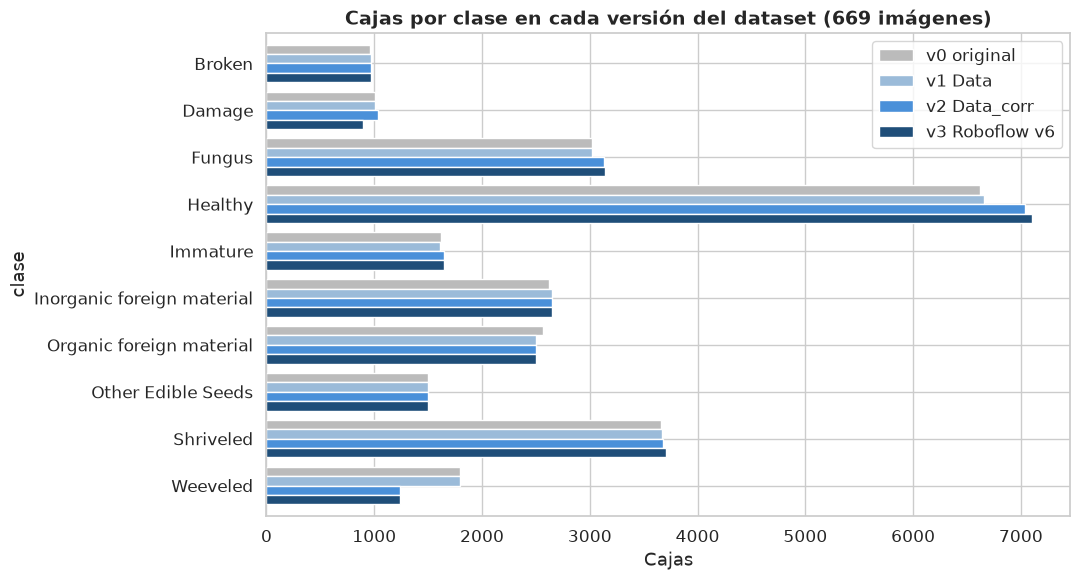

In [3]:
ax = conteo.drop('TOTAL').plot(kind='barh', figsize=(11, 6), width=0.8, color=['#BBBBBB', '#9BBBD9', '#4A90D9', '#1F4E79'])
ax.invert_yaxis(); ax.set_xlabel('Cajas'); ax.set_title('Cajas por clase en cada versión del dataset (669 imágenes)')
plt.tight_layout(); plt.savefig(SALIDA / 'cajas_por_version.png', dpi=130, bbox_inches='tight'); plt.show()

## 2. Cambios entre versiones

Las cajas de dos versiones se emparejan por IoU ≥ 0.5 en la misma imagen:
- **reclasificada:** misma caja, otra clase;
- **reajustada:** misma clase, pero la caja cambió de forma (IoU < 0.95);
- **eliminada** / **añadida:** sin pareja en la otra versión.

In [4]:
nombres = list(versiones)
cambios, resumen = {}, []
for a, b in zip(nombres, nombres[1:]):
    c = Q.comparar(versiones[a], versiones[b])
    cambios[(a, b)] = c
    fila = {'transición': f'{a} → {b}', 'imágenes modificadas': c.base.nunique()}
    fila.update(c.tipo.value_counts().reindex(['añadida', 'eliminada', 'reclasificada', 'reajustada']).fillna(0).astype(int).to_dict())
    resumen.append(fila)
resumen = pd.DataFrame(resumen)
resumen

,transición,imágenes modificadas,añadida,eliminada,reclasificada,reajustada
0,v0 original → v1 Data,90,130,120,52,756
1,v1 Data → v2 Data_corr,36,14,14,559,631
2,v2 Data_corr → v3 Roboflow v6,44,0,22,148,25


In [5]:
for (a, b), c in cambios.items():
    r = c[c.tipo == 'reclasificada']
    print(f'{a} → {b}: principales reclasificaciones')
    display(r.groupby(['clase_antes', 'clase_despues']).size().sort_values(ascending=False).head(8).rename('cajas').to_frame())

v0 original → v1 Data: principales reclasificaciones


,,cajas
clase_antes,clase_despues,
Organic foreign material,Inorganic foreign material,30
Immature,Shriveled,8
Damage,Healthy,2
Fungus,Healthy,2
Weeveled,Healthy,2
Immature,Broken,2
Damage,Broken,1
Immature,Damage,1


v1 Data → v2 Data_corr: principales reclasificaciones


cajas
clase_antes clase_despues       
Weeveled    Healthy          381
            Fungus           117
            Immature          29
            Damage            26
            Shriveled          5
Healthy     Weeveled           1

v2 Data_corr → v3 Roboflow v6: principales reclasificaciones


cajas
clase_antes clase_despues       
Damage      Healthy           87
            Shriveled         30
Healthy     Fungus            14
Damage      Broken             7
            Weeveled           6
            Immature           4

### Ejemplo visual de cada transición (imagen con más cajas añadidas o reclasificadas; color = clase)

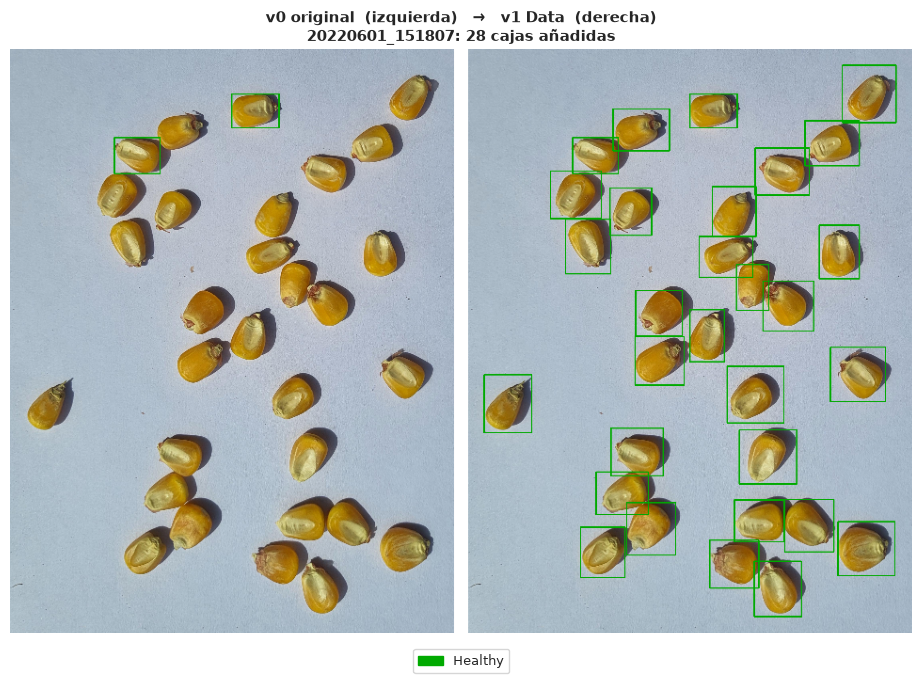

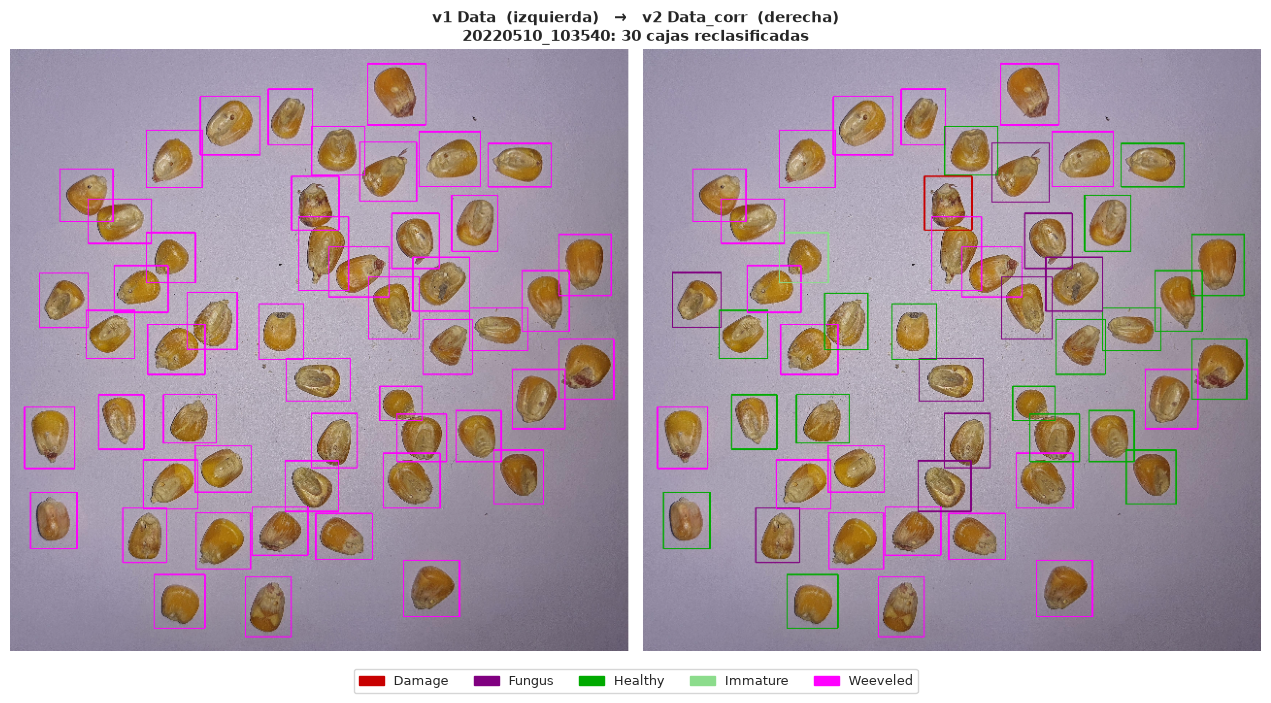

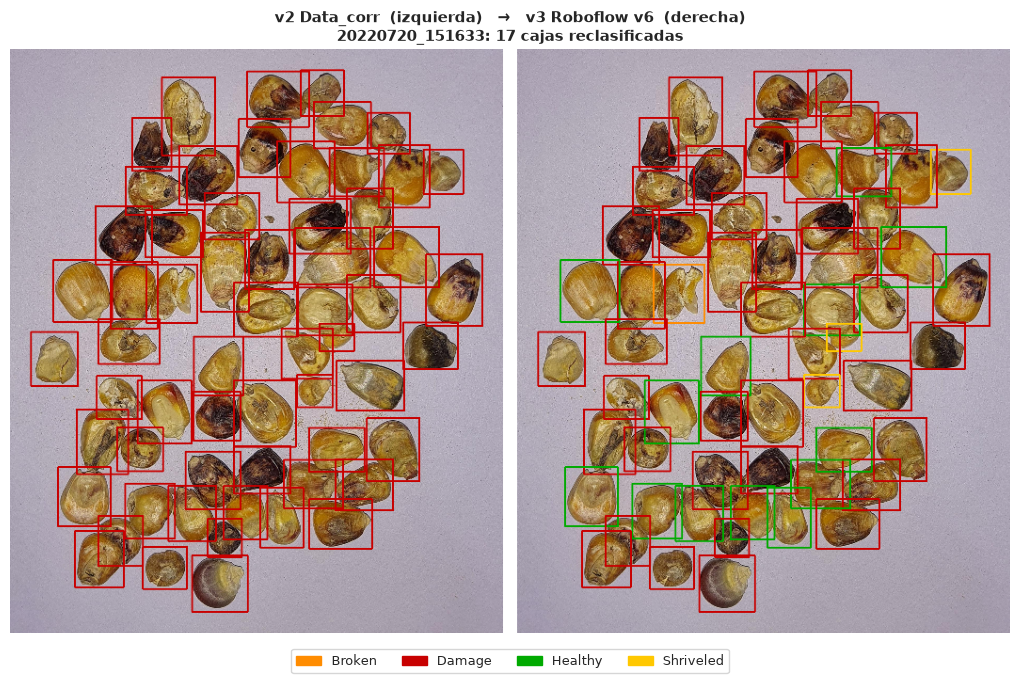

In [6]:
COLORES = {'Broken': (0, 140, 255), 'Damage': (0, 0, 200), 'Fungus': (128, 0, 128), 'Healthy': (0, 170, 0),
           'Immature': (140, 220, 140), 'Inorganic foreign material': (200, 120, 0), 'Organic foreign material': (255, 200, 0),
           'Other Edible Seeds': (120, 120, 120), 'Shriveled': (0, 200, 255), 'Weeveled': (255, 0, 255)}

def panel(r, zona, alto=620):
    """Recorta la misma zona en las dos versiones para que tengan la misma escala."""
    img = cv2.imread(str(r['img'])); xs = r['xyxy']
    x0, y0 = int(max(0, zona[:, 0].min() - 80)), int(max(0, zona[:, 1].min() - 80))
    x1, y1 = int(min(r['W'], zona[:, 2].max() + 80)), int(min(r['H'], zona[:, 3].max() + 80))
    rec = img[y0:y1, x0:x1].copy()
    for b, c in zip(xs, r['clases']):
        cv2.rectangle(rec, (int(b[0]) - x0, int(b[1]) - y0), (int(b[2]) - x0, int(b[3]) - y0), COLORES[Q.CLASES[c]], 6)
    return cv2.resize(rec, None, fx=alto / rec.shape[0], fy=alto / rec.shape[0])

TIPO_PRINCIPAL = {('v0 original', 'v1 Data'): 'añadida', ('v1 Data', 'v2 Data_corr'): 'reclasificada',
                  ('v2 Data_corr', 'v3 Roboflow v6'): 'reclasificada'}
for (a, b), c in cambios.items():
    base = c[c.tipo == TIPO_PRINCIPAL[(a, b)]].base.value_counts().index[0]
    ra = next(r for r in versiones[a] if r['base'] == base); rb = next(r for r in versiones[b] if r['base'] == base)
    zona = np.vstack([ra['xyxy'], rb['xyxy']])
    pa, pb = panel(ra, zona), panel(rb, zona)
    lienzo = np.hstack([pa, np.full((pa.shape[0], 15, 3), 255, np.uint8), pb])
    fig, ax = plt.subplots(figsize=(14, 7))
    ax.imshow(cv2.cvtColor(lienzo, cv2.COLOR_BGR2RGB)); ax.axis('off')
    detalle = ', '.join(f"{n} {'caja' if n == 1 else 'cajas'} {t}{'' if n == 1 else 's'}"
                        for t, n in c[c.base == base].tipo.value_counts().items())
    ax.set_title(f'{a}  (izquierda)   →   {b}  (derecha)\n{Q.nombre_roboflow(ra["stem"])}: {detalle}', fontsize=11)
    usadas = sorted({Q.CLASES[k] for k in ra['clases'] + rb['clases']})
    ax.legend(handles=[plt.Rectangle((0, 0), 1, 1, color=np.array(COLORES[n][::-1]) / 255) for n in usadas], labels=usadas,
              loc='lower center', bbox_to_anchor=(0.5, -0.08), ncol=len(usadas), fontsize=9)
    nombre = f"antes_despues_{a.split()[0]}_{b.split()[0]}.png"
    plt.tight_layout(); plt.savefig(SALIDA / nombre, dpi=120, bbox_inches='tight'); plt.show()

## 3. Problemas detectados en cada versión

Los mismos controles del EDA aplicados a cada versión muestran el efecto de las correcciones.

In [7]:
problemas_por_version = {k: Q.detectar(inv) for k, inv in versiones.items()}
tabla = pd.DataFrame({k: d.tipo.value_counts() for k, d in problemas_por_version.items()}).fillna(0).astype(int)
tabla.loc['TOTAL'] = tabla.sum()
tabla

,v0 original,v1 Data,v2 Data_corr,v3 Roboflow v6
tipo,,,,
Caja degenerada,13,6,6,0
Cajas duplicadas,16,16,16,0
Clase rara en sesión casi monoclase,13,14,14,2
Posible etiquetado incompleto,1,0,0,0
Tamaño atípico,13,0,0,0
TOTAL,56,36,36,2


### Problemas que quedan en la versión actual

In [8]:
residuales = problemas_por_version['v3 Roboflow v6']
residuales[['tipo', 'base', 'split', 'detalle']]

,tipo,base,split,detalle
0,Clase rara en sesión casi monoclase,20220720_154640_jpg,test,Broken (1 de 60 cajas) en una sesión de Damage
1,Clase rara en sesión casi monoclase,20220720_154640_jpg,test,Shriveled (1 de 60 cajas) en una sesión de Damage


## 4. Dataset limpio: 669 imágenes originales de la v6

In [9]:
# Se reconstruye solo si está la exportación completa de Roboflow v6 (762 imágenes);
# si no, se usa el dataset limpio ya construido.
if EXPORT_V6.exists():
    todas_v6 = Q.leer_dataset(EXPORT_V6)
    if LIMPIO.exists():
        shutil.rmtree(LIMPIO)
    for r in todas_v6:
        if r['base'] in ORIGINALES:
            for sub, origen in (('images', r['img']), ('labels', r['lbl'])):
                (LIMPIO / r['split'] / sub).mkdir(parents=True, exist_ok=True)
                shutil.copy2(origen, LIMPIO / r['split'] / sub / origen.name)
    shutil.copy2(EXPORT_V6 / 'data.yaml', LIMPIO / 'data.yaml')
    print(f"Excluidas {len({r['base'] for r in todas_v6} - ORIGINALES)} imágenes nuevas de la ampliación")

limpio = Q.leer_dataset(LIMPIO)
assert len(limpio) == 669 and {r['base'] for r in limpio} == ORIGINALES, 'El dataset limpio no tiene exactamente las 669 originales'
print(f'{LIMPIO}: {len(limpio)} imágenes, {sum(len(r["clases"]) for r in limpio)} cajas')
pd.Series({s: sum(r['split'] == s for r in limpio) for s in Q.SPLITS}, name='imágenes').to_frame()

/home/ismael/Documents/Tesis/maiz-yolo11/datos/Data_corr_v6: 669 imágenes, 25364 cajas


,imágenes
train,468
valid,134
test,67


## 5. Conclusiones

- **v0 → v1:** se completaron imágenes con granos sin etiquetar, se corrigieron clases mal asignadas (sobre todo entre impurezas orgánicas e inorgánicas) y se eliminaron trazos accidentales.
- **v1 → v2:** curaduría de `Weeveled`: los granos sin orificio visible se reasignaron según lo que se ve.
- **v2 → v3:** se eliminaron las cajas duplicadas y degeneradas detectadas en el EDA, y se aplicó el mismo criterio de la clase visible a `Damage` y a las clases raras de cada bandeja.
- Los problemas detectables pasan de 56 en el original a 2 en la versión actual.